In [9]:
!pip install torch numpy matplotlib


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python3.13 -m pip install --upgrade pip


In [11]:
%pip install opencv-python torch numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 6.4 MB/s  0:00:07m0:00:0100:01

[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


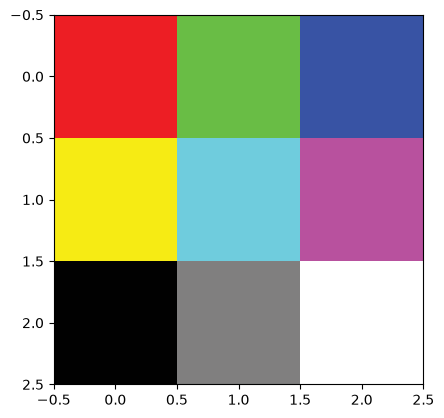

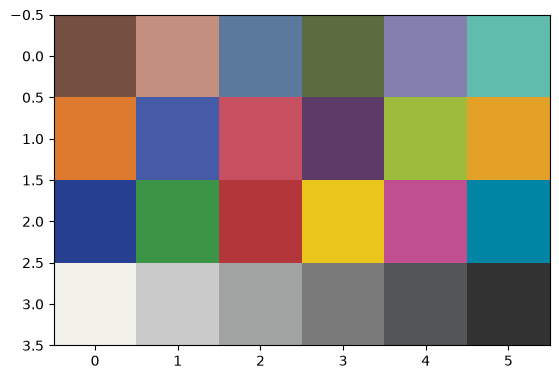

In [15]:
# 推論データ
X =  np.array([[0.77, 0.10, 0.06],
               [0.22, 0.86, 0.17],
               [0.95, 0.19, 0.31],
               [0.95, 1.00, 0.24],
               [0.29, 0.97, 0.75],
               [0.39, 0.15, 0.24],
               [0.00, 0.00, 0.00],
               [0.12, 0.25, 0.15],
               [1.00, 1.00, 1.00],

               [0.11, 0.04, 0.00],
               [0.41, 0.41, 0.19],
               [0.10, 0.29, 0.27],
               [0.05, 0.15, 0.03],
               [0.19, 0.35, 0.35],
               [0.25, 0.85, 0.44],

               [0.55, 0.29, 0.05],
               [0.05, 0.18, 0.30],
               [0.43, 0.13, 0.11],
               [0.05, 0.01, 0.08],
               [0.34, 0.80, 0.14],
               [0.66, 0.60, 0.12],

               [0.05, 0.08, 0.21],
               [0.08, 0.39, 0.06],
               [0.28, 0.00, 0.00],
               [0.63, 0.84, 0.11],
               [0.35, 0.10, 0.18],
               [0.06, 0.39, 0.34],

               [0.90, 1.00, 0.87],
               [0.56, 0.94, 0.55],
               [0.29, 0.49, 0.28],
               [0.12, 0.19, 0.11],
               [0.03, 0.05, 0.03],
               [0.00, 0.00, 0.00]], dtype=np.float32)

img1 = cv2.resize(cv2.imread("img/reference_image1_cmyk_large.png", cv2.IMREAD_COLOR_RGB), (3,3), interpolation=cv2.INTER_NEAREST)
img2 = cv2.resize(cv2.imread("img/reference_image2_cmyk_large.png", cv2.IMREAD_COLOR_RGB), (6,4), interpolation=cv2.INTER_NEAREST)

plt.imshow(img1)
plt.show()
plt.imshow(img2)
plt.show()

# 正解データ
Y = np.concatenate([img1.reshape([-1, 3])/255, img2.reshape([-1, 3])/255], axis=0).astype(np.float32)

In [16]:
X_tensor = torch.tensor(X, dtype=torch.float32)
Y_tensor = torch.tensor(Y, dtype=torch.float32)

# モデル定義
class ColorNet(nn.Module):
    def __init__(self):
        super(ColorNet, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(3, 40),
            nn.ReLU(),
            nn.Linear(40, 40),
            nn.ReLU(),
            nn.Linear(40, 3),
        )

    def forward(self, x):
        return self.model(x)

model = ColorNet()

# 損失関数（MSE）
criterion = nn.MSELoss()

# 最適化手法
optimizer = optim.Adam(model.parameters(), lr=0.01)

# L1正則化の係数
lambda_l1 = 1e-6

# 学習ループ
epochs = 50000
for epoch in range(epochs):
    optimizer.zero_grad()

    outputs = model(X_tensor)
    mse = criterion(outputs, Y_tensor)

    # --- L1 正則化-----------------------------
    l1 = torch.tensor(0.0, requires_grad=False)
    for name, p in model.named_parameters():
        if 'weight' in name:
            l1 = l1 + p.abs().sum()
    loss = mse + lambda_l1 * l1
    # -----------------------------------------

    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f'Epoch [{epoch}/{epochs}]  MSE: {mse.item():.6f}  L1: {l1.item():.2f}  Loss: {loss.item():.6f}')

with torch.no_grad():
    predictions = model(X_tensor)
    print("\n予測結果：")
    print(predictions.numpy())

def convert_to_cpp_array(tensor: torch.Tensor, name: str, dtype: str = "float"):
    flat = tensor.detach().numpy().flatten()
    array_str = f"{dtype} {name}[] = {{"
    array_str += ", ".join(map(str, flat))
    array_str += "};"
    return array_str

cpp_code = ""

layer_idx = 1
for layer in model.model:
    if isinstance(layer, torch.nn.Linear):
        cpp_code += convert_to_cpp_array(layer.weight, f"weight_{layer_idx}") + "\n"
        cpp_code += convert_to_cpp_array(layer.bias,   f"bias_{layer_idx}") + "\n"
        layer_idx += 1

with open("model_parameters.h", "w") as f:
    f.write(cpp_code)

print("\nC++ 用のパラメータファイル (model_parameters.h) を作成しました。")


Epoch [0/50000]  MSE: 0.387025  L1: 168.77  Loss: 0.387193
Epoch [500/50000]  MSE: 0.000899  L1: 139.49  Loss: 0.001039
Epoch [1000/50000]  MSE: 0.000645  L1: 133.62  Loss: 0.000779
Epoch [1500/50000]  MSE: 0.000622  L1: 126.29  Loss: 0.000748
Epoch [2000/50000]  MSE: 0.000586  L1: 121.06  Loss: 0.000707
Epoch [2500/50000]  MSE: 0.000579  L1: 116.00  Loss: 0.000695
Epoch [3000/50000]  MSE: 0.000567  L1: 110.75  Loss: 0.000678
Epoch [3500/50000]  MSE: 0.000564  L1: 106.33  Loss: 0.000670
Epoch [4000/50000]  MSE: 0.000603  L1: 102.50  Loss: 0.000706
Epoch [4500/50000]  MSE: 0.000577  L1: 99.46  Loss: 0.000676
Epoch [5000/50000]  MSE: 0.000605  L1: 96.13  Loss: 0.000701
Epoch [5500/50000]  MSE: 0.000570  L1: 93.49  Loss: 0.000663
Epoch [6000/50000]  MSE: 0.000562  L1: 91.34  Loss: 0.000653
Epoch [6500/50000]  MSE: 0.000562  L1: 89.28  Loss: 0.000651
Epoch [7000/50000]  MSE: 0.000566  L1: 87.68  Loss: 0.000654
Epoch [7500/50000]  MSE: 0.000715  L1: 85.90  Loss: 0.000801
Epoch [8000/50000] 

In [ ]:
#####ニューラルネットワーク前（学習させる用）と後は，環境を揃えること！！！！！！！！！！！！！！！！！！